In [1]:
import os
import pickle
import numpy as np
from PAOFLOW import PAOFLOW
from PAOFLOW import GPAO
from PAOFLOW.models.band_unfold import unfold_bands, plot_unfolded, FCC_SYM_POINTS, FCC_PATH
from PAOFLOW.models.edtb_params import EDTBModel

pplt = GPAO.GPAO()

Ry2eV = 13.60569193


In [2]:

# ═══════════════════════════════════════════════════════════════════════
#  Input normalization: raw PAOFLOW (arry, attr) → EDTB-style model dict
# ═══════════════════════════════════════════════════════════════════════


def paoflow_to_model_dict(arry: dict, attr: dict) -> dict:
    r"""Map a raw PAOFLOW ``(arry, attr)`` pair to the EDTB-style model dict.

    The already-built real-space Hamiltonian ``HRs`` and its lattice vector
    grid ``R`` are carried over under the private key ``_paoflow`` so that
    :func:`_extract_hamiltonian` can reuse them instead of rebuilding them.

    In Quantum ESPRESSO / PAOFLOW, ``a_vectors`` are stored in alat units,
    whereas ``tau`` is stored in Bohr.  This function converts ``tau`` to
    Cartesian/alat units by dividing by ``alat``:

    .. math::
        \boldsymbol{\tau}_{\mathrm{alat}} =
        \frac{\boldsymbol{\tau}_{\mathrm{Bohr}}}{a_{\mathrm{lat}}}.

    The orbital count per atom is inferred uniformly as

    .. math::
        n_{\mathrm{orb}} = \frac{n_{\mathrm{awf}}}{n_{\mathrm{atoms}}},

    where :math:`n_{\mathrm{awf}}` is the total number of orbitals and
    :math:`n_{\mathrm{atoms}}` is the number of atoms in the cell.

    Parameters
    ----------
    arry : dict
        PAOFLOW arrays dictionary.
    attr : dict
        PAOFLOW attributes dictionary.

    Returns
    -------
    dict
        A model dictionary compatible with :func:`unfold_bands`.
    """
    alat = float(attr.get('alat', 1.0))
    a_vectors = np.array(arry['a_vectors'], dtype=float)
    tau = np.array(arry['tau'], dtype=float) / alat  # Bohr → Cartesian/alat
    natoms = int(attr.get('natoms', len(tau)))

    species = arry.get('atoms', None)
    atoms = {}
    for i in range(natoms):
        name = species[i] if species is not None and i < len(species) else 'X'
        atoms[str(i)] = {'name': name, 'tau': tau[i].tolist()}

    HRs = np.array(arry['HRs'])
    nawf, nspin = HRs.shape[0], HRs.shape[-1]
    if HRs.ndim == 6:
        # nawf, _, nk1, nk2, nk3, nspin = HRs.shape
        HRs = HRs.reshape(nawf, nawf, -1, nspin)
    R = np.array(arry['R'], dtype=float)
    
    # R = get_R_grid_fft_1(a_vectors,nk1,nk2,nk3)
    # print(R == arry['R'])
    norbitals = np.full(natoms, nawf // natoms, dtype=int)

    return {
        'label': 'PAOFLOW',
        'alat': alat,
        'model': {'a_vectors': a_vectors, 'atoms': atoms},
        '_paoflow': {
            'HRs': HRs.copy(), 'R': R.copy(),
            'nawf': int(nawf), 'nspin': int(nspin), 'norbitals': norbitals,
        },
    }

# EDTB workflow

In [3]:
_SK_PARAMS = 'Silicon/Si_SK_params.json'
_SK_GEOM   = 'Silicon/Si_geometry.json'

print(f"Loading bulk EDTB model from {_SK_PARAMS} ...")
model = EDTBModel.from_files(_SK_PARAMS, _SK_GEOM)
print(model)


Loading bulk EDTB model from Silicon/Si_SK_params.json ...
EDTBModel  [SK_EDTB]  alat=10.5995 Bohr
  geometry: 2 atoms, species=['Si']
EDTB Parameters  (v1.0)
  Converted from 'SK_EDTB' model

Species: Si
  Si: l_channels=['s', 'p', 'd'], norb=9
    onsite: s=-3.7672, p=1.8840, t2g=5.5524, eg=5.4923

Hopping blocks: 1 species pairs
  Si-Si: 3 shells
    shell 1: r_ref=4.58968 Bohr, 10 params
    shell 2: r_ref=7.494997 Bohr, 10 params
    shell 3: r_ref=8.788663 Bohr, 10 params

Screening: r_cut=8.0 Bohr
  γ[Si-Si]: ss=0.0270, sp=0.0066, sd=0.0220, pp=-0.0130, pd=0.0193, dd=0.0676


In [4]:
# ═══════════════════════════════════════════════════════════
# Band unfolding: 8-atom SC → 2-atom FCC Brillouin zone
# (uses the general-purpose band_unfold module)
# ═══════════════════════════════════════════════════════════

# Load PC and SC models
model_fcc_uf = EDTBModel.from_files("Silicon/Si_SK_params.json", "Silicon/Si_geometry.json")
model_sc_uf  = EDTBModel.from_files("Silicon/Si_SK_params.json", "Silicon/Si_geometry_sc8.json")

md_fcc = model_fcc_uf.to_model_dict()
md_sc  = model_sc_uf.to_model_dict()

# Run unfolding (fully automatic: finds M, translations, atom mapping)
result = unfold_bands(md_fcc, md_sc,
                      sym_points=FCC_SYM_POINTS,
                      path_str=FCC_PATH,
                      nk_per_seg=80, 
                      verbose=True)

Transformation matrix M (det = 4):
  [-1  1 -1]
  [-1  1  1]
  [ 1  1 -1]
Found 4 translations inside SC.

Atom mapping (PC atom α → SC atom I):
  α=0: SC atoms [0, 3, 2, 1]
  α=1: SC atoms [4, 7, 6, 5]

Building PC Hamiltonian...

────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
──────────────────────────────────────────────────────────────────

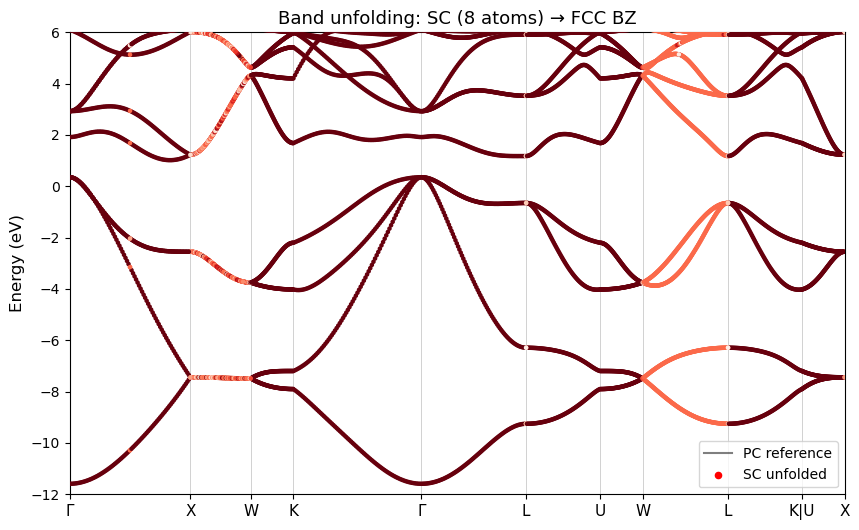

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Band unfolding: SC (8 atoms) → FCC BZ'}, ylabel='Energy (eV)'>)

In [5]:
# Plot
plot_unfolded(result, y_lim=(-12, 6),
              title="Band unfolding: SC (8 atoms) → FCC BZ")

# QE workflow

In [6]:
# Primitive cell PAOFLOW run
paoflow_pc = PAOFLOW.PAOFLOW(savedir='Silicon/Si_bulk.save', outputdir='pc_out')
paoflow_pc.projections(basispath='BASIS_PS', configuration='standard')
paoflow_pc.projectability()
paoflow_pc.pao_hamiltonian()
paoflow_pc.bands(ibrav=2, nk=801, fname='bands')
arry_pc, attr_pc = paoflow_pc.data_controller.data_dicts()

# Supercell PAOFLOW run
paoflow_sc = PAOFLOW.PAOFLOW(savedir='Silicon/Si_supercell.save', outputdir='sc4_out')
paoflow_sc.projections(basispath='BASIS_PS', configuration='standard')
paoflow_sc.projectability()
paoflow_sc.pao_hamiltonian()
paoflow_sc.bands(ibrav=1, nk=801, fname='bands')
arry_sc, attr_sc = paoflow_sc.data_controller.data_dicts()



────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Estimated maximum array size: 0.07 GBytes

Initialization in:                          0.008 sec
Projections in:                             1.173 sec
Projectability in:                         

In [7]:
pao_dict_pc = paoflow_to_model_dict(arry_pc, attr_pc)
pao_dict_sc = paoflow_to_model_dict(arry_sc, attr_sc)

In [8]:
result_qe = unfold_bands(
    pao_dict_pc,
    pao_dict_sc,
    sym_points=FCC_SYM_POINTS,
    path_str=FCC_PATH,
    nk_per_seg=80,
    verbose=True
)

Transformation matrix M (det = 8):
  [-1  1 -1]
  [-1  1  1]
  [ 2  2 -2]
Found 8 translations inside SC.

Atom mapping (PC atom α → SC atom I):
  α=0: SC atoms [0, 8, 3, 11, 2, 10, 1, 9]
  α=1: SC atoms [4, 12, 7, 15, 6, 14, 5, 13]

Building PC Hamiltonian...
Building SC Hamiltonian...

PC: 26 orbitals,  SC: 208 orbitals,  N=8
Expected sum rule: Σ_n W_n(k) = 26
k-path: 802 points, 11 symmetry ticks

Sum rule:  Σ_n W_n(k)  mean = 26.000000  (expected 26),  max deviation = 1.42e-14


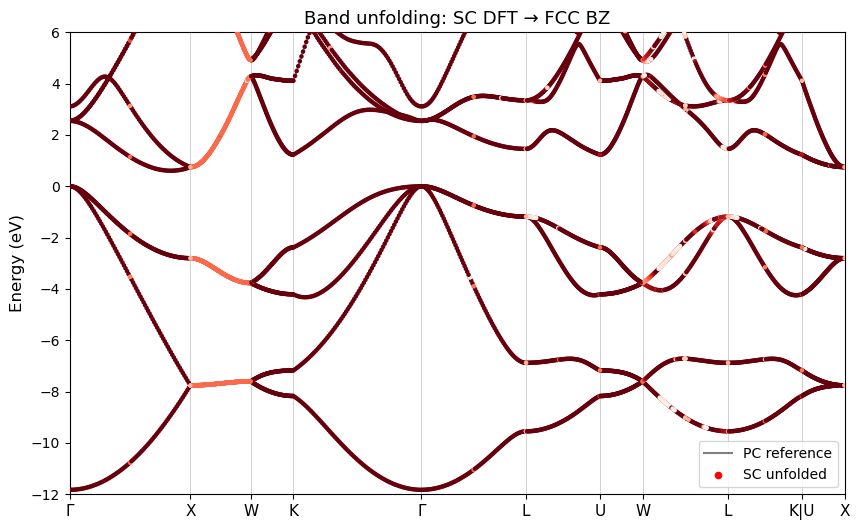

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Band unfolding: SC DFT → FCC BZ'}, ylabel='Energy (eV)'>)

In [9]:
plot_unfolded(result_qe, y_lim=(-12, 6), 
              title="Band unfolding: SC DFT → FCC BZ")